# Case - 1 OUR RNN Based Only Solar Past Power

A chronological D to D+1 solar power forecast using only past `Act. Power (MW)`. No weather, calendar, or future time features are used.

# 1. Project Configuration

Imports, paths, artifact locations, and configuration variables are defined in the next cell.

In [ ]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import (
    Input,
    Masking,
    SimpleRNN,
    Dense,
    Concatenate,
    RepeatVector,
    TimeDistributed,
    Reshape,
)
from tensorflow.keras.models import Model, load_model

artifact_dir = Path(r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks")
model_path = artifact_dir / "scenario1_encoder_decoder.keras"
scaler_path = artifact_dir / "scenario1_scaler.joblib"
results_path = artifact_dir / "scenario1_test_results.npz"

W_TRAIN = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Training.xlsx"
W_VALIDATION = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Val.xlsx"
W_TEST = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Test.xlsx"

# 2. Load Dataset

Load the existing chronological Excel datasets and inspect their row/day counts. No raw data or split files are changed.

In [11]:
def load_data(train_path, validation_path, test_path):
    """Load the three existing chronological Excel splits without re-splitting."""
    train = pd.read_excel(train_path)
    validation = pd.read_excel(validation_path)
    test = pd.read_excel(test_path)

    for split in (train, validation, test):
        split['TimeStamp'] = pd.to_datetime(split['TimeStamp'])
        split['Date'] = split['TimeStamp'].dt.date
        split.sort_values('TimeStamp', inplace=True)
        split.reset_index(drop=True, inplace=True)

    return train, validation, test


W_TRAIN = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Training.xlsx"
W_VALIDATION = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Val.xlsx"
W_TEST = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Test.xlsx"

train, validation, test = load_data(W_TRAIN, W_VALIDATION, W_TEST)

print('Train days      :', train['Date'].nunique())
print('Validation days :', validation['Date'].nunique())
print('Test days       :', test['Date'].nunique())
print()
print('Train rows      :', len(train))
print('Validation rows :', len(validation))
print('Test rows       :', len(test))

Train days      : 86
Validation days : 30
Test days       : 7

Train rows      : 8256
Validation rows : 2880
Test rows       : 672


# 3. Train / Validation / Test Split

The notebook uses the existing chronological Excel splits without re-splitting or shuffling the datasets.

# 4. Revision Sample Creation

Put the existing revision lengths, target length, padded input length, sample creator, and train/validation/test sample creation in this section.

In [33]:
REVISION_LENGTHS = {
    'R0': 32,
    'R1': 50,
    'R2': 64,
    'R3': 82,
}
TARGET_LENGTH = 96
PADDED_INPUT_LENGTH = 82
BLOCKS_PER_DAY = 96
POWER_COLUMN = 'Act. Power (MW)'
def create_revision_samples(split):
    sample_dates = []
    """Create real D -> D+1 samples; padding is added after scaling."""
    day_groups = {
        date: day_data.sort_values('TimeStamp')
        for date, day_data in split.groupby('Date', sort=True)
    }
    X = []
    y = []
    revision_labels = []
    revision_sample_indices = {revision: [] for revision in REVISION_LENGTHS}
    for day, day_data in day_groups.items():
        next_day = (pd.Timestamp(day) + pd.Timedelta(days=1)).date()
        next_day_data = day_groups.get(next_day)
        if next_day_data is None or len(day_data) < PADDED_INPUT_LENGTH:
            continue
        if len(next_day_data) != TARGET_LENGTH:
            continue
        day_power = day_data[POWER_COLUMN].to_numpy(dtype=np.float32)
        next_day_power = next_day_data[POWER_COLUMN].to_numpy(dtype=np.float32)
        for revision, sequence_length in REVISION_LENGTHS.items():
            history = day_power[:sequence_length, np.newaxis]
            sample_index = len(X)
            X.append(history)
            y.append(next_day_power)
            revision_labels.append(revision)
            sample_dates.append(next_day)
            revision_sample_indices[revision].append(sample_index)
    return (
    X,
    np.asarray(y, dtype=np.float32),
    np.asarray(revision_labels),
    revision_sample_indices,
    np.asarray(sample_dates),
)
X_train, y_train, revision_labels_train, revision_indices_train, dates_train = create_revision_samples(train)

X_validation, y_validation, revision_labels_validation, revision_indices_validation, dates_validation = create_revision_samples(validation)

X_test, y_test, revision_labels_test, revision_indices_test, dates_test = create_revision_samples(test)
revision_info = {
    'lengths': REVISION_LENGTHS,
    'train': revision_indices_train,
    'validation': revision_indices_validation,
    'test': revision_indices_test,
}
for split_name, X_split, y_split, labels in (
    ('Train', X_train, y_train, revision_labels_train),
    ('Validation', X_validation, y_validation, revision_labels_validation),
    ('Test', X_test, y_test, revision_labels_test),
):
    revision_counts = dict(zip(*np.unique(labels, return_counts=True)))
    # print(f'{split_name}: {len(labels)} samples')
    # print(f'  Raw X lengths: {[sample.shape for sample in X_split[:4]]}')
    # print(f'  y shape: {y_split.shape}')
    # print(f'  Revision counts: {revision_counts}')

In [34]:
from sklearn.preprocessing import MinMaxScaler
# Fit only on real training power values from the raw training dataframe.
scaler = MinMaxScaler()
scaler.fit(train[[POWER_COLUMN]].to_numpy())

train_power_scaled = scaler.transform(train[[POWER_COLUMN]].to_numpy())
val_power_scaled = scaler.transform(validation[[POWER_COLUMN]].to_numpy())
test_power_scaled = scaler.transform(test[[POWER_COLUMN]].to_numpy())

# 5. Preprocessing and Scaling

This section preserves the existing `MinMaxScaler`, time features, padding, and scaled input creation.

In [35]:
# Scale real power, add block-time features, then pad all three input channels with -1.
def time_features(block_indices):
    block_indices = np.asarray(block_indices, dtype=np.float32)
    phase = 2.0 * np.pi * block_indices / BLOCKS_PER_DAY
    return np.column_stack((np.sin(phase), np.cos(phase))).astype(np.float32)
def preprocess_revision_samples(X_raw, y_raw, revision_labels, scaler):
    X_processed = np.full(
        (len(X_raw), PADDED_INPUT_LENGTH, 3),
        -1.0,
        dtype=np.float32,
    )
    y_scaled = scaler.transform(y_raw.reshape(-1, 1)).reshape(y_raw.shape).astype(np.float32)

    for revision, real_length in REVISION_LENGTHS.items():
        revision_mask = revision_labels == revision
        real_power = np.asarray(
            [sample[:, 0] for sample, is_revision in zip(X_raw, revision_mask) if is_revision],
            dtype=np.float32,
        )
        scaled_power = scaler.transform(real_power.reshape(-1, 1)).reshape(
            -1, real_length
        )
        temporal_features = time_features(np.arange(real_length))
        X_processed[revision_mask, :real_length, 0] = scaled_power
        X_processed[revision_mask, :real_length, 1:] = temporal_features

    return X_processed, y_scaled
X_train_scaled, y_train_scaled = preprocess_revision_samples(
    X_train, y_train, revision_labels_train, scaler
)
X_validation_scaled, y_validation_scaled = preprocess_revision_samples(
    X_validation, y_validation, revision_labels_validation, scaler
)
X_test_scaled, y_test_scaled = preprocess_revision_samples(
    X_test, y_test, revision_labels_test, scaler
)
for split_name, X_scaled, y_scaled, labels in (
    ('Train', X_train_scaled, y_train_scaled, revision_labels_train),
    ('Validation', X_validation_scaled, y_validation_scaled, revision_labels_validation),
    ('Test', X_test_scaled, y_test_scaled, revision_labels_test),
):
    print(f'{split_name}: X shape={X_scaled.shape}, y shape={y_scaled.shape}')
    assert X_scaled.shape[1:] == (PADDED_INPUT_LENGTH, 3)
    assert y_scaled.shape[1:] == (TARGET_LENGTH,)
    for revision, real_length in REVISION_LENGTHS.items():
        revision_mask = labels == revision
        sample_input = X_scaled[revision_mask][0]
        padding = X_scaled[revision_mask, real_length:, :]
        assert np.all(padding == -1.0)
        assert np.all(np.isfinite(sample_input[:real_length]))
        assert np.allclose(
            sample_input[:real_length, 1:],
            time_features(np.arange(real_length)),
        )
        print(
            f'  {revision}: {real_length} real + '
            f'{PADDED_INPUT_LENGTH - real_length} padding'
        )
print()
print('Example input block/time by revision:')
for revision, real_length in REVISION_LENGTHS.items():
    sample_index = int(np.flatnonzero(revision_labels_train == revision)[0])
    sample_input = X_train_scaled[sample_index]
    first_block = 0
    last_block = real_length - 1
    print(
        f'  {revision}: first block {first_block} '
        f'({first_block // 4:02d}:{(first_block % 4) * 15:02d}), '
        f'last block {last_block} '
        f'({last_block // 4:02d}:{(last_block % 4) * 15:02d}), '
        f'first features={sample_input[first_block]}, '
        f'last features={sample_input[last_block]}'
    )

assert np.allclose(time_features([0])[0], [0.0, 1.0])
assert np.allclose(
    time_features([95])[0][0],
    np.sin(2.0 * np.pi * 95 / 96),
)
# print('Target block 0 = 00:00 and target block 95 = 23:45.')
# print('Preprocessing checks passed: power is scaled, time features use actual blocks, and padding is exactly -1.')

Train: X shape=(340, 82, 3), y shape=(340, 96)
  R0: 32 real + 50 padding
  R1: 50 real + 32 padding
  R2: 64 real + 18 padding
  R3: 82 real + 0 padding
Validation: X shape=(116, 82, 3), y shape=(116, 96)
  R0: 32 real + 50 padding
  R1: 50 real + 32 padding
  R2: 64 real + 18 padding
  R3: 82 real + 0 padding
Test: X shape=(24, 82, 3), y shape=(24, 96)
  R0: 32 real + 50 padding
  R1: 50 real + 32 padding
  R2: 64 real + 18 padding
  R3: 82 real + 0 padding

Example input block/time by revision:
  R0: first block 0 (00:00), last block 31 (07:45), first features=[0. 0. 1.], last features=[ 0.27548078  0.89687276 -0.44228864]
  R1: first block 0 (00:00), last block 49 (12:15), first features=[0. 0. 1.], last features=[ 0.8730769  -0.06540333 -0.9978589 ]
  R2: first block 0 (00:00), last block 63 (15:45), first features=[0. 0. 1.], last features=[ 0.7653846 -0.8314697 -0.55557  ]
  R3: first block 0 (00:00), last block 81 (20:15), first features=[0. 0. 1.], last features=[ 0.        -0

# 6. Reproducibility

This section must run before model creation or training.

In [ ]:
import os
import random

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()

print(f"Reproducibility configured with seed {SEED}.")

# 7. Model Architecture

This section contains only the existing encoder-decoder model definition.

In [19]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Masking,
    SimpleRNN,
    Dense,
    Concatenate,
    RepeatVector,
    TimeDistributed,
    Reshape,
)
from tensorflow.keras.callbacks import EarlyStopping

encoder_input = Input(
    shape=(PADDED_INPUT_LENGTH, 3),
    name='encoder_input',
)
masked_encoder_input = Masking(
    mask_value=-1.0,
    name='encoder_masking',
)(encoder_input)
encoder_context = SimpleRNN(
    64,
    name='encoder_rnn',
)(masked_encoder_input)

future_time_input = Input(
    shape=(TARGET_LENGTH, 2),
    name='future_time_input',
)
repeated_context = RepeatVector(
    TARGET_LENGTH,
    name='repeat_context',
)(encoder_context)
decoder_input = Concatenate(
    axis=-1,
    name='decoder_features',
)([repeated_context, future_time_input])
decoder_sequence = SimpleRNN(
    64,
    return_sequences=True,
    name='decoder_rnn',
)(decoder_input)
block_predictions = TimeDistributed(
    Dense(1),
    name='block_prediction',
)(decoder_sequence)
forecast = Reshape(
    (TARGET_LENGTH,),
    name='forecast',
)(block_predictions)

model = Model(
    inputs=[encoder_input, future_time_input],
    outputs=forecast,
)
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae'],
)

assert model.input_shape == [(None, PADDED_INPUT_LENGTH, 3), (None, TARGET_LENGTH, 2)]
assert model.output_shape == (None, TARGET_LENGTH)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 82, 3)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 82, 3)     │          0 │ encoder_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_masking     │ (None, 82, 3)     │          0 │ encoder_input[0]… │
│ (Masking)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any_1 (Any)         │ (None, 82)        │          0 │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_rnn         │ (None, 64)        │      4,352 │ encoder_masking[… │
│ (SimpleRNN)         │                   │            │ any_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_context      │ (None, 96, 64)    │          0 │ encoder_rnn[0][0] │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ future_time_input   │ (None, 96, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_features    │ (None, 96, 66)    │          0 │ repeat_context[0… │
│ (Concatenate)       │                   │            │ future_time_inpu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_rnn         │ (None, 96, 64)    │      8,384 │ decoder_features… │
│ (SimpleRNN)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_prediction    │ (None, 96, 1)     │         65 │ decoder_rnn[0][0] │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ forecast (Reshape)  │ (None, 96)        │          0 │ block_prediction… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 12,801 (50.00 KB)

 Trainable params: 12,801 (50.00 KB)

 Non-trainable params: 0 (0.00 B)

# 8. Model Training

**RUN ONLY WHEN TRAINING THE MODEL**  
**DO NOT RUN FOR DEMO**

In [22]:
future_time = time_features(np.arange(TARGET_LENGTH))
future_time_train = np.tile(
    future_time,
    (len(X_train_scaled), 1, 1),
).astype(np.float32)
future_time_validation = np.tile(
    future_time,
    (len(X_validation_scaled), 1, 1),
).astype(np.float32)
future_time_test = np.tile(
    future_time,
    (len(X_test_scaled), 1, 1),
).astype(np.float32)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
)

history = model.fit(
    [X_train_scaled, future_time_train],
    y_train_scaled,
    validation_data=(
        [X_validation_scaled, future_time_validation],
        y_validation_scaled,
    ),
    epochs=150,
    batch_size=16,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1,
)

complete_training_days = [
    day_data[POWER_COLUMN].to_numpy(dtype=np.float32)
    for _, day_data in train.groupby('Date', sort=True)
    if len(day_data) == BLOCKS_PER_DAY
]
complete_training_power = np.asarray(complete_training_days)
active_fraction = np.mean(complete_training_power > 0.1, axis=0)
night_blocks = np.where(active_fraction < 0.10)[0]

artifact_dir = Path(r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks")
model_path = artifact_dir / "scenario1_encoder_decoder.keras"
scaler_path = artifact_dir / "scenario1_scaler.joblib"
model.save(model_path)
joblib.dump(scaler, scaler_path)

print(f"Training completed after {len(history.history['loss'])} epochs.")
print(f"Model saved to: {model_path}")
print(f"Scaler saved to: {scaler_path}")

Epoch 1/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 10s 129ms/step - loss: 0.1453 - mae: 0.2831 - val_loss: 0.0358 - val_mae: 0.1536
Epoch 2/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - loss: 0.0455 - mae: 0.1731 - val_loss: 0.0273 - val_mae: 0.1367
Epoch 3/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - loss: 0.0369 - mae: 0.1608 - val_loss: 0.0255 - val_mae: 0.1321
Epoch 4/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - loss: 0.0314 - mae: 0.1476 - val_loss: 0.0224 - val_mae: 0.1246
Epoch 5/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - loss: 0.0290 - mae: 0.1411 - val_loss: 0.0190 - val_mae: 0.1142
Epoch 6/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - loss: 0.0257 - mae: 0.1303 - val_loss: 0.0154 - val_mae: 0.0995
Epoch 7/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - loss: 0.0227 - mae: 0.1179 - val_loss: 0.0124 - val_mae: 0.0875
Epoch 8/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - loss: 0.0205 - mae: 0.1087 - val_loss: 0.0106 - val_mae: 0.0782
Epoch 9/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 118ms/step 

# 9. Training Evaluation

Training-only loss visualization. **DO NOT RUN FOR DEMO.**

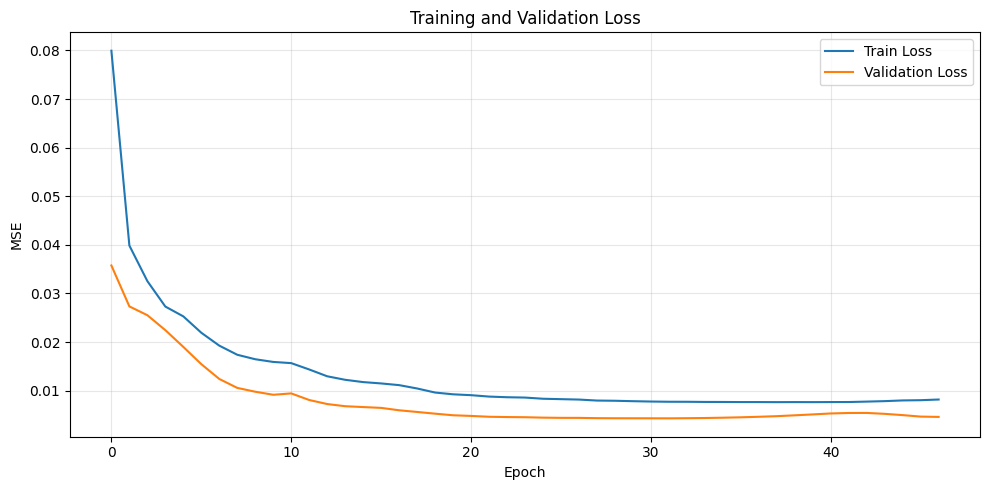

In [ ]:
# TRAINING ONLY: requires history from the Model Training section.
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Training and Validation Loss')

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 10. Test Prediction and Metrics

**RUN ONLY WHEN GENERATING NEW PREDICTIONS**  
This section preserves model prediction, inverse scaling, nighttime constraint, and overall/revision-wise MAE, RMSE, and R².

In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prediction
predicted_scaled = model.predict(
    [X_test_scaled, future_time_test],
    verbose=0,
)

y_pred = scaler.inverse_transform(
    predicted_scaled.reshape(-1, 1)
).reshape(-1, TARGET_LENGTH)

y_actual = scaler.inverse_transform(
    y_test_scaled.reshape(-1, 1)
).reshape(-1, TARGET_LENGTH)


# Physical constraint
y_pred = np.maximum(y_pred, 0.0)


# Data-derived nighttime constraint
complete_training_days = [
    day_data[POWER_COLUMN].to_numpy(dtype=np.float32)
    for _, day_data in train.groupby('Date', sort=True)
    if len(day_data) == BLOCKS_PER_DAY
]

complete_training_power = np.asarray(complete_training_days)

active_fraction = np.mean(
    complete_training_power > 0.1,
    axis=0
)

night_blocks = np.where(active_fraction < 0.10)[0]

y_pred[:, night_blocks] = 0.0


# Overall metrics
overall_mae = mean_absolute_error(
    y_actual.ravel(),
    y_pred.ravel()
)

overall_rmse = np.sqrt(
    mean_squared_error(
        y_actual.ravel(),
        y_pred.ravel()
    )
)

overall_r2 = r2_score(
    y_actual.ravel(),
    y_pred.ravel()
)

print(f'Overall MAE  = {overall_mae:.4f} MW')
print(f'Overall RMSE = {overall_rmse:.4f} MW')
print(f'Overall R²   = {overall_r2:.4f}')


# Revision-wise metrics
for revision, indices in revision_indices_test.items():

    indices = np.asarray(indices, dtype=int)

    revision_actual = y_actual[indices].ravel()
    revision_pred = y_pred[indices].ravel()

    revision_mae = mean_absolute_error(
        revision_actual,
        revision_pred
    )

    revision_rmse = np.sqrt(
        mean_squared_error(
            revision_actual,
            revision_pred
        )
    )

    revision_r2 = r2_score(
        revision_actual,
        revision_pred
    )

    print(
        f'{revision}: '
        f'MAE = {revision_mae:.4f} MW, '
        f'RMSE = {revision_rmse:.4f} MW, '
        f'R² = {revision_r2:.4f}'
    )

Overall MAE  = 0.9439 MW
Overall RMSE = 1.6754 MW
Overall R²   = 0.9521
R0: MAE = 1.1547 MW, RMSE = 2.0503 MW, R² = 0.9283
R1: MAE = 0.8048 MW, RMSE = 1.4078 MW, R² = 0.9662
R2: MAE = 0.8303 MW, RMSE = 1.5125 MW, R² = 0.9610
R3: MAE = 0.9859 MW, RMSE = 1.6596 MW, R² = 0.9530


# 11. Save Test Results

Save `y_actual`, `y_pred`, `revision_labels_test`, and `dates_test` to `scenario1_test_results.npz`. **RUN AFTER NEW PREDICTIONS ONLY.**

In [40]:
results_path = artifact_dir / "scenario1_test_results.npz"

np.savez(
    results_path,
    y_actual=y_actual,
    y_pred=y_pred,
    revision_labels=revision_labels_test,
    dates_test=dates_test.astype(str),
)

print(f"Results saved to: {results_path}")

Results saved to: C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\scenario1_test_results.npz


# 12. Results / Demonstration

**DEMO / RESULTS ONLY**  
This section loads the saved `.npz` file and generates presentation plots without loading the model or calling `model.fit()`. It is safe to run after restarting the kernel.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import r2_score

artifact_dir = Path(r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks")
results_path = artifact_dir / "scenario1_test_results.npz"
TARGET_LENGTH = 96

results = np.load(results_path, allow_pickle=True)
y_actual = results["y_actual"]
y_pred = results["y_pred"]
revision_labels_test = results["revision_labels"]
dates_test = results["dates_test"]
revision_indices_test = {
    revision: np.flatnonzero(revision_labels_test == revision)
    for revision in ("R0", "R1", "R2", "R3")
}

print(results.files)
print("Actual:", y_actual.shape)
print("Predicted:", y_pred.shape)
print("Revisions:", revision_labels_test.shape)
print("Dates:", dates_test.shape)
print("Unique dates:", np.unique(dates_test))

['y_actual', 'y_pred', 'revision_labels', 'dates_test']
Actual: (24, 96)
Predicted: (24, 96)
Revisions: (24,)
Dates: (24,)
Dates: ['2026-02-09' '2026-02-10' '2026-02-11' '2026-02-12' '2026-02-13'
 '2026-02-14']


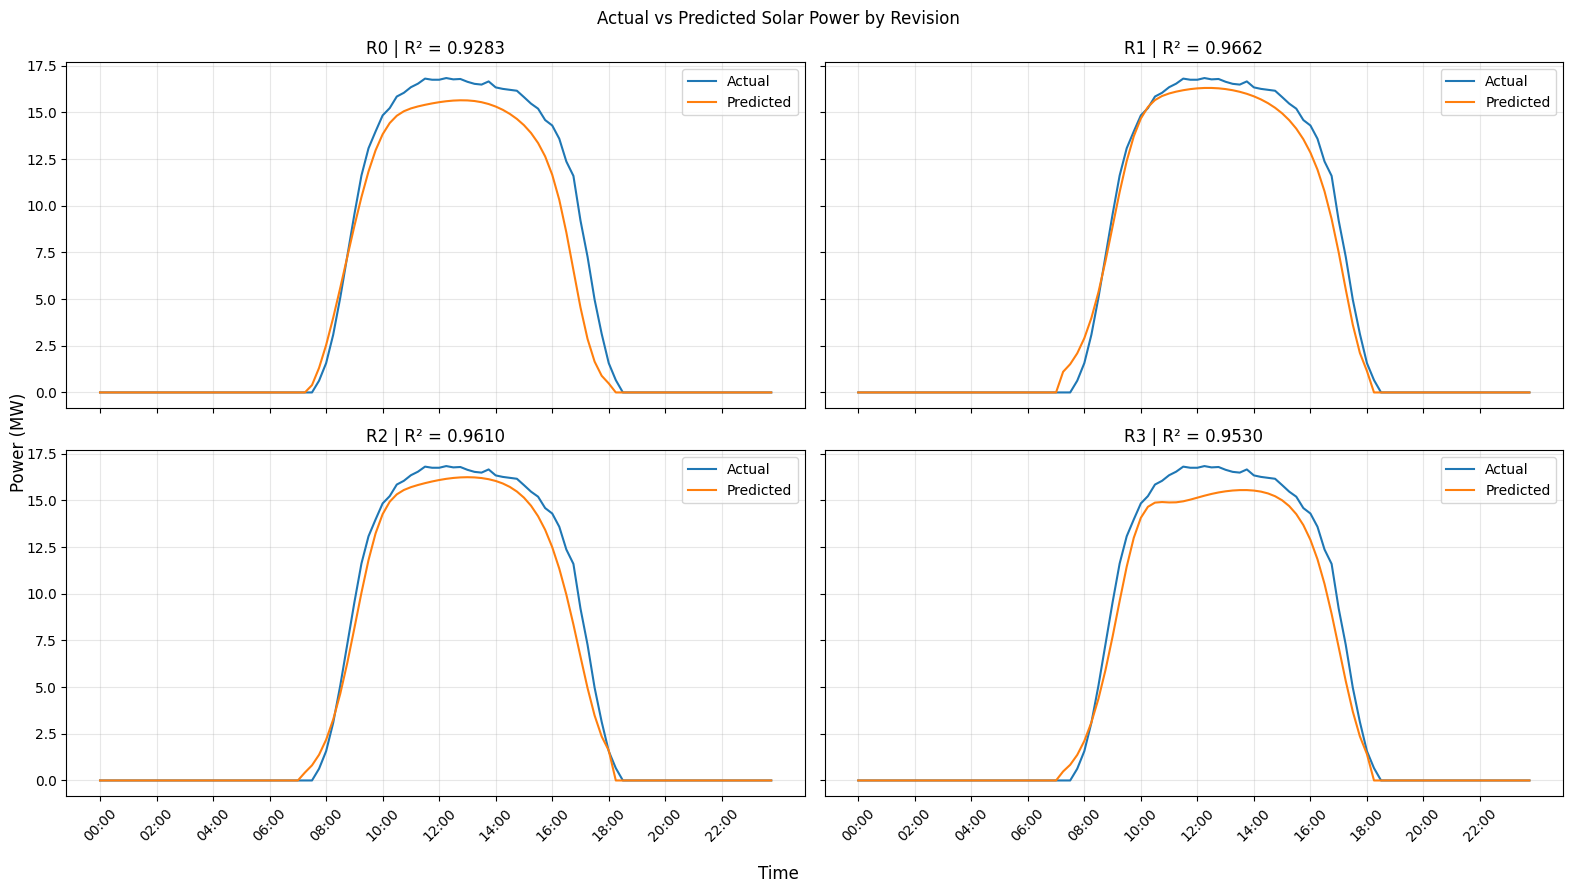

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

block_labels = [
    f'{block // 4:02d}:{(block % 4) * 15:02d}'
    for block in range(TARGET_LENGTH)
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 9),
    sharex=True,
    sharey=True
)

for axis, (revision, indices) in zip(
    axes.ravel(),
    revision_indices_test.items()
):
    indices = np.asarray(indices, dtype=int)

    # First test sample for this revision
    sample_index = int(indices[0])

    # R² for this revision across all its test samples
    revision_r2 = r2_score(
        y_actual[indices].ravel(),
        y_pred[indices].ravel()
    )

    axis.plot(
        y_actual[sample_index],
        label='Actual',
        linewidth=1.5
    )

    axis.plot(
        y_pred[sample_index],
        label='Predicted',
        linewidth=1.5
    )

    axis.set_title(
        f'{revision} | R² = {revision_r2:.4f}'
    )

    axis.set_xticks(
        np.arange(0, TARGET_LENGTH, 8)
    )

    axis.set_xticklabels(
        [block_labels[i] for i in range(0, TARGET_LENGTH, 8)],
        rotation=45
    )

    axis.grid(True, alpha=0.3)
    axis.legend()

fig.supxlabel('Time')
fig.supylabel('Power (MW)')
fig.suptitle('Actual vs Predicted Solar Power by Revision')

fig.tight_layout()
plt.show()

DSM BAND CALCULATION

In [46]:
# DSM ±7% BAND

DSM_TOLERANCE = 0.07

dsm_lower = y_actual * (1 - DSM_TOLERANCE)
dsm_upper = y_actual * (1 + DSM_TOLERANCE)

print("DSM band calculated.")

DSM band calculated.


In [47]:
# ORGANIZE TEST RESULTS BY DAY AND REVISION

test_dates = np.unique(dates_test)

print("Test days:")
for date in test_dates:
    print(date)

print(f"\nNumber of test days: {len(test_dates)}")
print(f"Number of forecasts: {len(y_pred)}")

Test days:
2026-02-09
2026-02-10
2026-02-11
2026-02-12
2026-02-13
2026-02-14

Number of test days: 6
Number of forecasts: 24


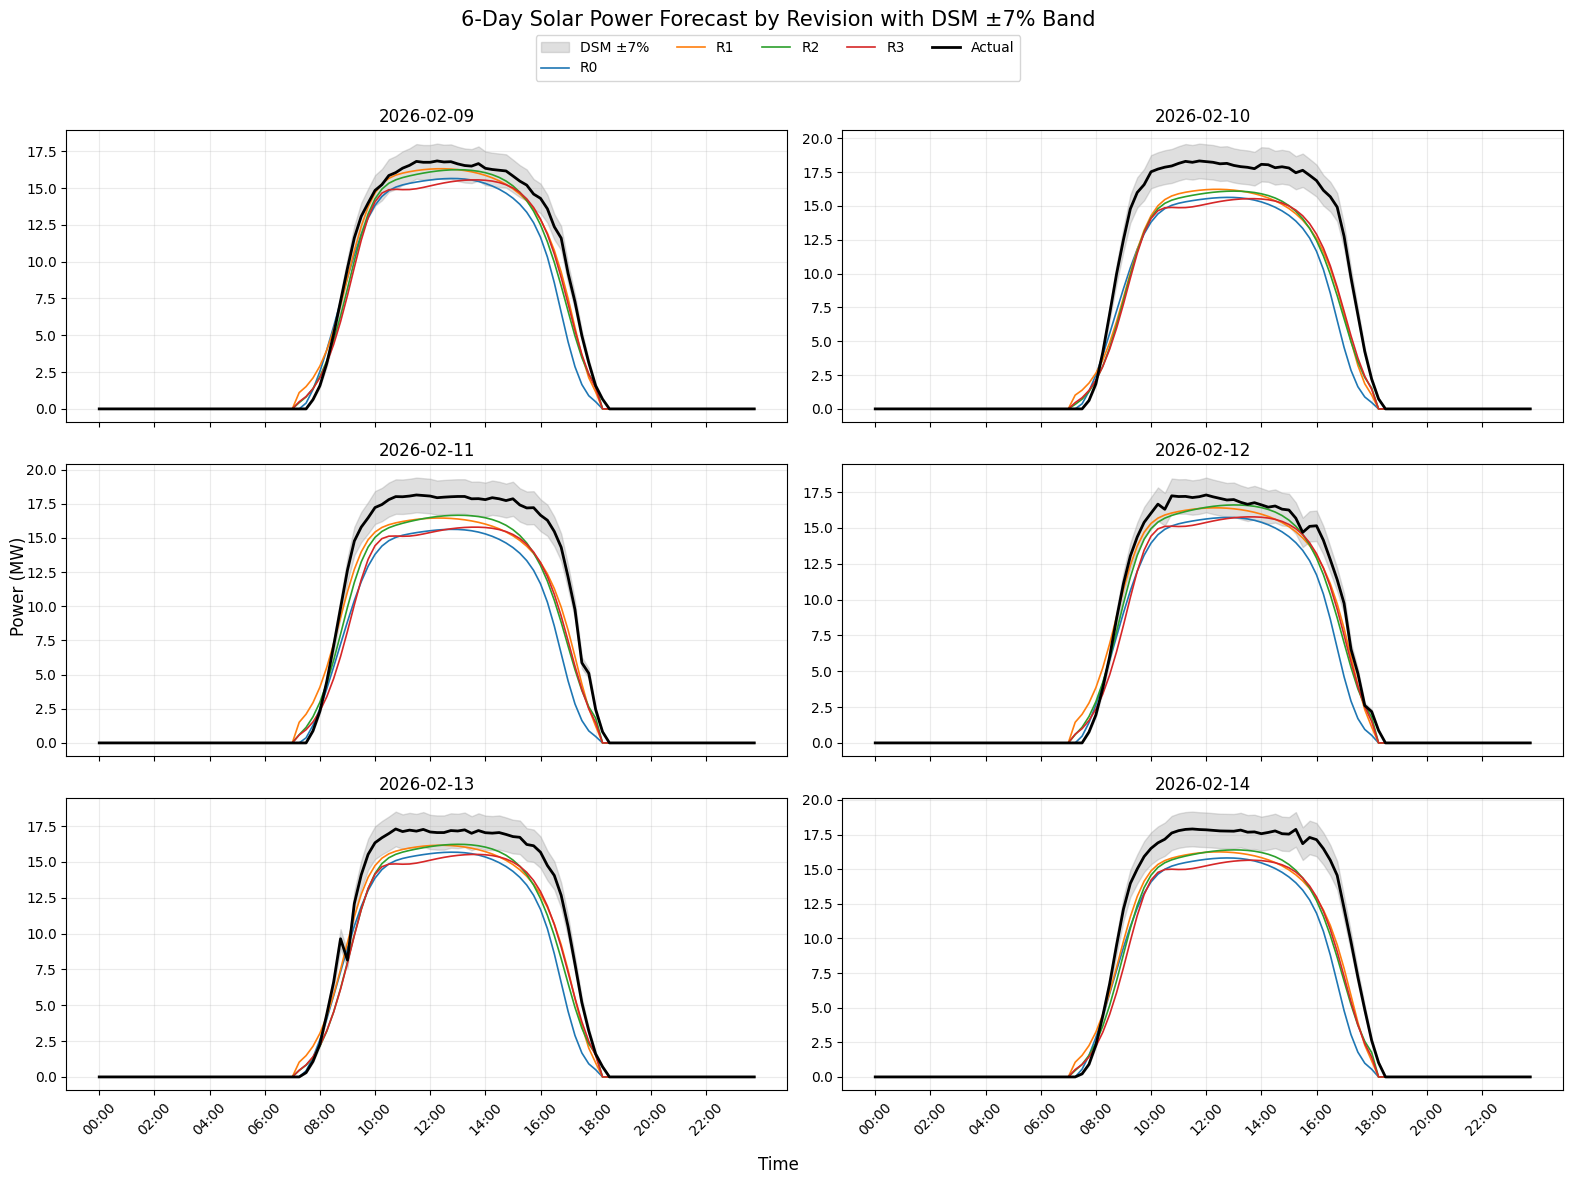

In [48]:
# 6-DAY DSM VISUALIZATION

import matplotlib.pyplot as plt

revision_order = ['R0', 'R1', 'R2', 'R3']

block_labels = [
    f'{block // 4:02d}:{(block % 4) * 15:02d}'
    for block in range(TARGET_LENGTH)
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(16, 12),
    sharex=True
)

for axis, date in zip(axes.ravel(), test_dates):

    date_mask = dates_test == date

    actual_index = np.where(date_mask)[0][0]
    actual = y_actual[actual_index]

    # DSM ±7% band around actual power
    lower = actual * 0.93
    upper = actual * 1.07

    axis.fill_between(
        np.arange(TARGET_LENGTH),
        lower,
        upper,
        color='gray',
        alpha=0.25,
        label='DSM ±7%'
    )

    for revision in revision_order:

        revision_index = np.where(
            date_mask & (revision_labels_test == revision)
        )[0][0]

        axis.plot(
            y_pred[revision_index],
            label=revision,
            linewidth=1.2
        )

    axis.plot(
        actual,
        label='Actual',
        linewidth=2,
        color='black'
    )

    axis.set_title(str(date))
    axis.set_xticks(np.arange(0, TARGET_LENGTH, 8))
    axis.set_xticklabels(
        [block_labels[i] for i in range(0, TARGET_LENGTH, 8)],
        rotation=45
    )
    axis.grid(True, alpha=0.25)

fig.supxlabel('Time')
fig.supylabel('Power (MW)')
fig.suptitle(
    '6-Day Solar Power Forecast by Revision with DSM ±7% Band',
    fontsize=15
)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='upper center',
    ncol=5,
    bbox_to_anchor=(0.5, 0.965)
)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

# 13. Optional / Experimental Cells

These cells are exploratory demonstrations or duplicate result checks. **DO NOT EXECUTE AUTOMATICALLY.**

In [31]:
results_path = artifact_dir / "scenario1_test_results.npz"

np.savez(
    results_path,
    y_actual=y_actual,
    y_pred=y_pred,
    revision_labels=revision_labels_test,
)

print(f"Test results saved to: {results_path}")

Test results saved to: C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\scenario1_test_results.npz


In [32]:
print(
    test.groupby('Date').size()
)

Date
2026-02-08    96
2026-02-09    96
2026-02-10    96
2026-02-11    96
2026-02-12    96
2026-02-13    96
2026-02-14    96
dtype: int64


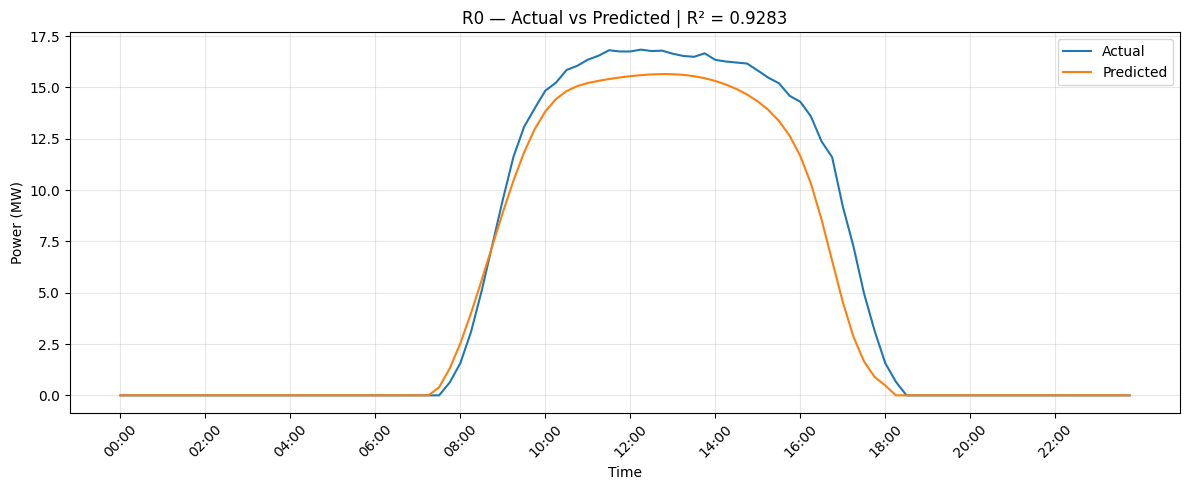

In [24]:
revision = 'R0'
indices = np.asarray(revision_indices_test[revision], dtype=int)
sample_index = int(indices[0])

revision_r2 = r2_score(
    y_actual[indices].ravel(),
    y_pred[indices].ravel()
)

block_labels = [
    f'{block // 4:02d}:{(block % 4) * 15:02d}'
    for block in range(TARGET_LENGTH)
]

plt.figure(figsize=(12, 5))
plt.plot(y_actual[sample_index], label='Actual')
plt.plot(y_pred[sample_index], label='Predicted')

plt.xlabel('Time')
plt.ylabel('Power (MW)')
plt.title(f'R0 — Actual vs Predicted | R² = {revision_r2:.4f}')

plt.xticks(
    np.arange(0, 96, 8),
    [block_labels[i] for i in range(0, 96, 8)],
    rotation=45
)

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()